### Network topology

In [6]:
# plot network topology

from pathlib import Path
import matplotlib.pyplot as plt
import sys
HERE = Path.cwd()

SRC = HERE.parent/'src'
sys.path.insert(0,str(SRC))

from transient_solver import *


In [7]:
run=transient_linepack()
print('Pipe length 15 km; diameter 0.30 m; source 40 bar(a)')
print('Pipe volume [m³]:',round(run['volume_m3'],1))
print('Initial gas inventory [tonnes]:',round(run['initial_mass_kg']/1000,2))

Pipe length 15 km; diameter 0.30 m; source 40 bar(a)
Pipe volume [m³]: 1060.3
Initial gas inventory [tonnes]: 28.25


## Step change in consumer withdrawal

Demand is 4 kg/s up to **20 min**, 6 kg/s from **20–60 min**, then 4 kg/s again. Initial conditions satisfy the steady equations. We integrate in three phases so the ODE integrator does not step across discontinuities without being told.

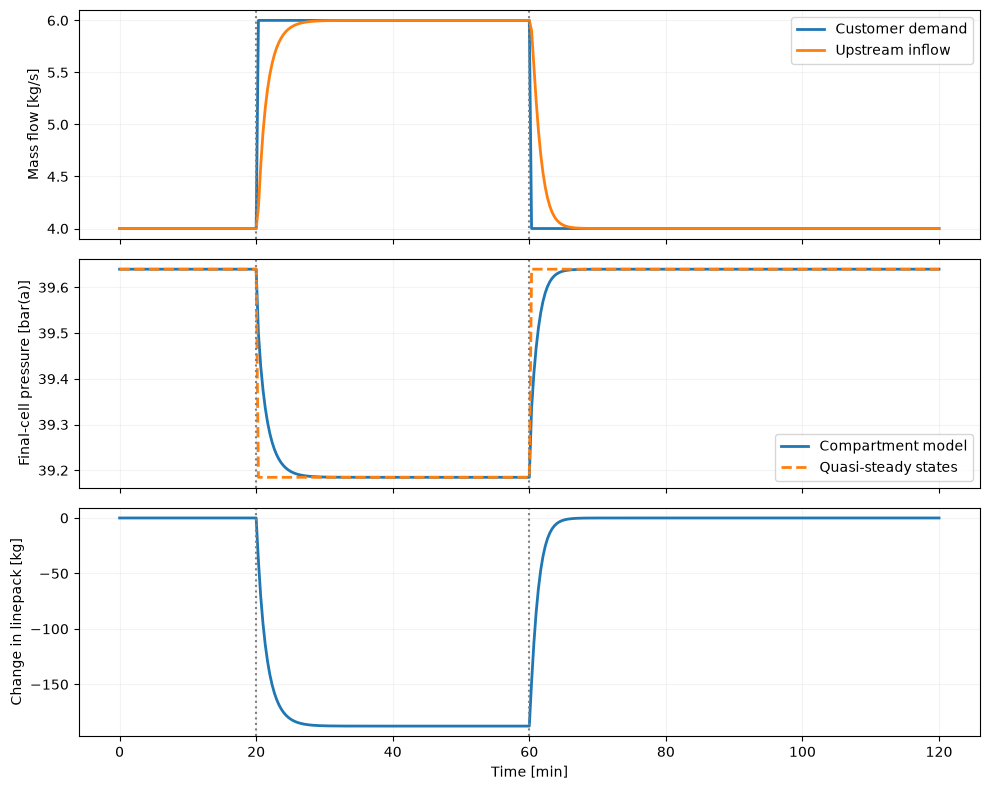

In [8]:
time=run['time_s']/60
fig,axes=plt.subplots(3,1,figsize=(10,8),sharex=True)
axes[0].plot(time,run['demand_kg_s'],lw=2,label='Customer demand')
axes[0].plot(time,run['flow_kg_s'][0],lw=2,label='Upstream inflow')
axes[0].set(ylabel='Mass flow [kg/s]');axes[0].legend()
axes[1].plot(time,run['pressure_bar'][-1],lw=2,label='Compartment model')
axes[1].plot(time,run['quasisteady_end_bar'],'--',lw=2,label='Quasi-steady states')
axes[1].set(ylabel='Final-cell pressure [bar(a)]');axes[1].legend()
axes[2].plot(time,run['inventory_kg']-run['initial_mass_kg'],lw=2)
axes[2].set(xlabel='Time [min]',ylabel='Change in linepack [kg]')
for ax in axes:ax.grid(alpha=.15);ax.axvline(20,color='grey',ls=':');ax.axvline(60,color='grey',ls=':')
plt.tight_layout();plt.show()

## Inventory conservation check

The global mass balance for all control volumes is


Compare change in stored mass with the numerical time integral of inlet minus outlet flow. The discrepancy is a check of integration and discretization error.

In [9]:
from scipy.integrate import trapezoid
balance_integral=trapezoid(run['flow_kg_s'][0]-run['demand_kg_s'], run['time_s'])
delta_inventory=run['inventory_kg'][-1]-run['inventory_kg'][0]
print('Integrated (inflow−demand) [kg]:',round(balance_integral,3))
print('Actual inventory change [kg]:',round(delta_inventory,3))
print('Difference [kg]:',round(delta_inventory-balance_integral,3))
print('Peak inventory release [kg]:',round(run['initial_mass_kg']-run['inventory_kg'].min(),2))

Integrated (inflow−demand) [kg]: 0.116
Actual inventory change [kg]: 0.0
Difference [kg]: -0.116
Peak inventory release [kg]: 187.67


### Exercise C

Predict the signs *immediately after* the 20-minute step (before running the plot):

1. Is gas injection flow less than, equal to or greater than the new withdrawal?
2. Is \(dM/dt\) positive or negative?
3. Will the outlet pressure initially jump (quasi-steady interpretation), or evolve continuously (compartment model)?
4. What is missing from this model for genuine fast-transient wave propagation?

## Spatial discretization and model order

Increasing the number of compartments changes time constants and spatial resolution. It does not automatically make the reduced model equivalent to a full momentum PDE.

Test 3, 6 and 12 cells, comparing end-of-pipeline pressure response.

In [ ]:
fig,ax=plt.subplots(figsize=(9,4))
for cells in [3,6,12]:
    sim=transient_linepack(num_cells=cells)
    ax.plot(sim['time_s']/60,sim['pressure_bar'][-1],lw=2,label=f'{cells} cells')
ax.set(xlabel='Time [min]',ylabel='Downstream pressure [bar(a)]')
ax.legend();ax.grid(alpha=.2);plt.show()

### Exercise D 

Change the pipeline diameter from 0.30 m to 0.40 m. Observe both effects:

- Increasing diameter increases volume \(V\propto D^2\), so more gas mass can be stored per bar.
- Increasing diameter reduces the friction coefficient \(K\propto D^{-5}\) (if friction factor stays constant).

**Question:** Why is it difficult to isolate only the linepack effect when changing diameter?

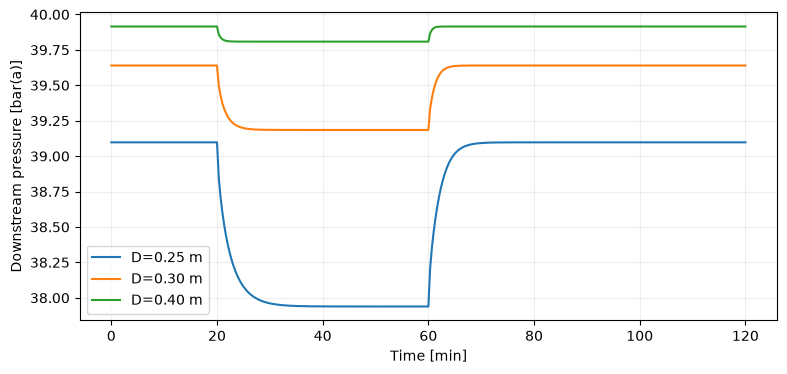

In [10]:
fig,ax=plt.subplots(figsize=(9,4))
for D in [0.25,0.30,0.40]:
    sim=transient_linepack(D=D)
    ax.plot(sim['time_s']/60,sim['pressure_bar'][-1],label=f'D={D:.2f} m')
ax.set(xlabel='Time [min]',ylabel='Downstream pressure [bar(a)]');ax.legend();ax.grid(alpha=.2);plt.show()